In [10]:
!python -m venv .venv
!source myenv/bin/activate
!python -m ipykernel install --user --name=myenv --display-name "Python (myenv)"
!pip install numpy pandas matplotlib 


zsh:source:1: no such file or directory: myenv/bin/activate
Installed kernelspec myenv in /Users/muhsilnr/Library/Jupyter/kernels/myenv


![Alt text](nnad.png)


In [11]:
!pip list

Package                 Version
----------------------- -----------
appnope                 1.0.0
asttokens               3.0.2
comm                    0.2.3
contourpy               1.4.0
cycler                  0.12.1
debugpy                 1.8.22
executing               2.2.1
fonttools               4.66.1
ipykernel               7.4.0
ipython                 9.17.1
ipython_pygments_lexers 1.1.1
jedi                    0.20.0
jupyter_client          8.10.0
jupyter_core            5.9.1
kiwisolver              1.5.1
matplotlib              3.11.2
matplotlib-inline       0.2.2
nest-asyncio2           1.7.3
numpy                   2.5.3
packaging               26.3
pandas                  3.0.6
parso                   0.8.7
pexpect                 4.9.0
pillow                  12.3.0
pip                     26.2.1
platformdirs            4.12.3
prompt_toolkit          3.0.53
psutil                  7.2.2
ptyprocess              0.7.0
pure_eval               0.2.4
Pygments              

In [12]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [13]:
data = pd.read_csv('train.csv')

In [5]:
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
data = np.array(data)
#m represents the number of images
#n reperesets the number of pixels
m,n = data.shape
#We randomize the data order because if the dataset
#in an order it affect the model perfomance
np.random.shuffle(data)

1. m is the total number of examples or image
2. n is the total number of (pixels/values) in an (example/image)

In [15]:
print(m,n)

42000 785


### Split the Data into two parts int Ration of 8:2
1. 80% for training
2. 20% for valuation

In [16]:
#Splitting the data into 80 percentage for training
train_data = data[0:int(0.8*m),:]
#Remaining data after splition 80 percentage for valuation
val_data= data[int(0.8*m):m, :]

### Now we split the data of training and valuation into 

1. Label (Y) 
2. Value (X)

#### The goal is tho map f(X) --> Y

In [17]:
#Actual data of images for training
#We want each column as the each image instead of each rows
#so we take transpose
X_train = train_data[:,1:].T 
#Convert the 0-255 pixel values scale down to 0 to 1 value
X_train = X_train/255.0
Y_train = train_data[:,0]
#Actual data of images for valuation
#first element in a row is label so we exclude the label slicing start form 1
#We want each column as the each image instead of each rows
#so we take transpose
X_val = val_data[:,1:].T
#Convert the 0-255 pixel values scale down to 0 to 1 value
X_val=X_val/255.0
Y_val = val_data[:,0]

In [18]:
print(X_val.shape)
print(Y_val.shape)
print(X_train.shape)
print(Y_train.shape)

(784, 8400)
(8400,)
(784, 33600)
(33600,)


Start with intializing the parameters

In [19]:
def intialize_parameters():
    W1 = np.random.rand(10, 784) - 0.5
    B1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    B2 = np.random.rand(10, 1) - 0.5
    return W1, B1, W2, B2
W1, B1, W2, B2 = intialize_parameters()
print(W1)


[[ 0.43486183 -0.42418067  0.20210388 ...  0.4241659   0.47367887
   0.16688808]
 [ 0.49546744 -0.35296085 -0.18615039 ... -0.10280593  0.1389661
  -0.20988178]
 [ 0.35361062 -0.46256097  0.23558184 ...  0.00422673  0.27499167
   0.10496132]
 ...
 [-0.31286393  0.40450458  0.36909769 ... -0.25179455 -0.29939535
  -0.06340559]
 [ 0.24226241 -0.08832057  0.40111431 ... -0.35522294  0.4580038
   0.23174823]
 [-0.06884548  0.30579408 -0.36047806 ... -0.1636486  -0.39363397
   0.45042853]]


#### Forward Propagation

In [20]:
def ReLU(X):
    return np.maximum(X,0)

def softmax_calculator(Z):
    return np.exp(Z) / sum(np.exp(Z))

def forward_propagation(W1, B1, W2, B2, X):
    Z1 = W1.dot(X) + B1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + B2
    A2 = softmax_calculator(Z2)
    return Z1, A1, Z2, A2

#### Backward Propagation

In [21]:
def one_hot_converter(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    return one_hot_Y.T

def backward_propagation(W1, B1, W2, B2, Z1, A1, Z2, A2, X, Y):
    one_hot_Y = one_hot_converter(Y)
    dZ2 = A2 - one_hot_Y
    dW2 = 1 / m * dZ2.dot(A1.T)
    dB2 = 1 / m * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2) * (Z1 > 0)
    dW1 = 1 / m * dZ1.dot(X.T)
    dB1 = 1 / m * np.sum(dZ1)
    return dW1, dB1, dW2, dB2

#### update Parameters

In [22]:
def update_parameters(W1,B1,W2,B2,dW1,dB1,dW2, dB2, learning_rate):
    W1 = W1 - learning_rate * dW1
    B1 = B1 - learning_rate * dB1
    W2 = W2 - learning_rate * dW2
    B2 = B2 - learning_rate * dB2
    return W1, B1, W2, B2

#### Get Prediction from last layer A2

In [23]:
def get_prediction(A2):
    return np.argmax(A2,0)

#### Get Accuracy

In [24]:
def get_accuracy(predictions, Y):
    return np.sum(predictions==Y)/Y.size 

#### Gradient descent

In [25]:
def gradient_descent(X,Y,alpha, iteration):
    W1, B1, W2, B2 = intialize_parameters()
    for i in range(iteration):
        Z1, A1, Z2, A2 = forward_propagation(W1, B1, W2, B2, X)
        dW1, dB1, dW2, dB2 = backward_propagation(W1, B1, W2, B2, Z1, A1, Z2, A2, X, Y)
        W1, B1, W2, B2 = update_parameters(W1, B1, W2, B2, dW1, dB1, dW2, dB2, alpha)
        if (i%10)==0:
            print("Iteration number: ",i)
            print("Accuracy: ",get_accuracy(get_prediction(A2),Y))

    return W1, B1, W2, B2

In [26]:
W1, B1, W2, B2 = gradient_descent(X_train, Y_train, 0.01, 12500 )

Iteration number:  0
Accuracy:  0.1119345238095238
Iteration number:  10
Accuracy:  0.11491071428571428
Iteration number:  20
Accuracy:  0.11922619047619047
Iteration number:  30
Accuracy:  0.12202380952380952
Iteration number:  40
Accuracy:  0.12505952380952381
Iteration number:  50
Accuracy:  0.1274404761904762
Iteration number:  60
Accuracy:  0.1305654761904762
Iteration number:  70
Accuracy:  0.13711309523809523
Iteration number:  80
Accuracy:  0.14375
Iteration number:  90
Accuracy:  0.14991071428571429
Iteration number:  100
Accuracy:  0.1581845238095238
Iteration number:  110
Accuracy:  0.17238095238095238
Iteration number:  120
Accuracy:  0.18348214285714284
Iteration number:  130
Accuracy:  0.1942559523809524
Iteration number:  140
Accuracy:  0.20398809523809525
Iteration number:  150
Accuracy:  0.21354166666666666
Iteration number:  160
Accuracy:  0.22303571428571428
Iteration number:  170
Accuracy:  0.23199404761904763
Iteration number:  180
Accuracy:  0.24080357142857142
It

Predicted Label:  [5]
Actual label:  5


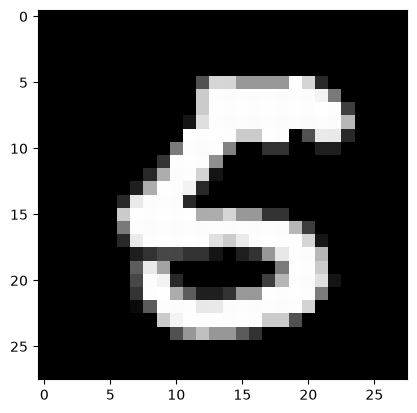

In [23]:
val_index=70
Z1val, A1val, Z2val, A2val = forward_propagation(W1, B1,W2, B2, X_val[:,val_index,None])
print("Predicted Label: ",get_prediction(A2val))
print("Actual label: ",Y_val[val_index])

image_array = X_val[:,val_index].reshape(28,28)
plt.imshow(image_array,cmap='gray')
plt.show()

In [24]:
Z1val, A1val, Z2val, A2val = forward_propagation(W1, B1,W2, B2, X_val)
val_acc=get_accuracy(get_prediction(A2val), Y_val)
print("Validation accuracy = ",val_acc)

Validation accuracy =  0.8797619047619047
